# Aprendizaje Automático I
## Práctica 1
Manuel Suano Gallardo

### 1. Importación de librerías

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import joblib

# Para el transformador personalizado
from sklearn.base import BaseEstimator, TransformerMixin

# Para el preprocesado
from category_encoders import BinaryEncoder
from sklearn.preprocessing import (
    OrdinalEncoder, KBinsDiscretizer, FunctionTransformer, RobustScaler, 
    StandardScaler
)
from sklearn.model_selection import train_test_split

# Para la construcción de pipelines
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import make_column_transformer

# Para los modelos
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, accuracy_score
)



### 2. Carga de datos y visualización previa

In [2]:
dataset_org = pd.read_csv('./airbnb.csv', sep=',')

Hacemos una visualización inicial de los datos.

In [3]:
dataset_org.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Centro,Justicia,40.424715,-3.698638,Entire home/apt,49,28,35,0.42,1,99
1,Centro,Embajadores,40.413418,-3.706838,Entire home/apt,80,5,18,0.30,1,188
2,Moncloa - Aravaca,Argüelles,40.424920,-3.713446,Entire home/apt,40,2,21,0.25,9,195
3,Moncloa - Aravaca,Casa de Campo,40.431027,-3.724586,Entire home/apt,55,2,3,0.13,9,334
4,Latina,Cármenes,40.403410,-3.740842,Private room,16,2,23,0.76,2,250


In [4]:
dataset_org.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  object 
 1   neighbourhood                   13321 non-null  object 
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  object 
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 1.1+ MB


Según el conteo, no sería necesario realizar ninguna interpolación de datos, pues todas las instancias tienen datos para cada una de las características.

No sería necesario, pero por preferencia personal voy a pasar el nombre de las características del inglés al español. Para ello simplemente generamos un diccionario con las traducciones.

In [5]:
traduccion_ing_2_esp = {
    'neighbourhood_group' 			: 'distrito',
    'neighbourhood'					: 'barrio',
    'latitude'						: 'latitud',
    'longitude'						: 'longitud',
    'room_type'						: 'tipo_habitacion',
    'price'							: 'precio',
    'minimum_nights'				: 'minimo_noches',
    'number_of_reviews'				: 'numero_opiniones',
    'reviews_per_month'				: 'opiniones_mes',
    'calculated_host_listings_count': 'numero_propiedades_host',
    'availability_365'				: 'disponibilidad_anual'
}

# Traducción inversa por si se quisiera volver al original
# traduccion_esp_2_ing = { nombre_esp : nombre_ing for nombre_ing, nombre_es in traduccion_ing_2_esp.items() }

dataset = dataset_org.rename(columns=traduccion_ing_2_esp)

Pasamos a realizar la separación de los datos: un 80% para entrenamiento y validación y un 20% para test. Sin embargo, al realizar la separación de forma aleatoria es posible que no se incluyan representación de alguno de los barrios debido a la baja frecuencia que tienen, como es el caso de El Pardo, Orcasitas, etc.

In [6]:
dataset[['barrio']].value_counts()

barrio        
Embajadores       1848
Universidad       1363
Palacio           1084
Sol                942
Justicia           788
                  ... 
Hellín               4
Santa Eugenia        4
Cuatro Vientos       3
Orcasitas            2
El Pardo             1
Name: count, Length: 126, dtype: int64

Para ello vamos a realizar una división de los datos manteniendo la representación de los barrios, al menos en el entrenamiento. Vamos a realizar una condificación _OneHot_, que después eliminaremos, para realizar el estratificado.

In [7]:
condificador = OrdinalEncoder()

dataset[['cat_barrio']] = condificador.fit_transform(dataset[['barrio']])

En el caso del barrio de El Pardo, al existir solo un único elemento en el conjunto, la función `train_test_split` con la opción de `stratify` no puede realizar la separación. Para ello extraeremos la instancia con dicho barrio y la añadiremos posteriormente al conjunto de entrenamiento.

In [8]:
barrio_El_Pardo = dataset[dataset['barrio'] == 'El Pardo']

dataset_sin_el_pardo = dataset.drop(barrio_El_Pardo.index.to_numpy())

dataset_train, dataset_test = train_test_split(dataset_sin_el_pardo, test_size=0.2, stratify=dataset_sin_el_pardo["cat_barrio"], random_state=0)

# Añadido del barrio El Pardo al conjunto de entrenamiento
dataset_train = pd.concat([dataset_train, barrio_El_Pardo])

Tras la división, la columna `cat_barrio` ya no es necesaria, por lo que se elimina de los datos

In [9]:
dataset_train = dataset_train.drop(['cat_barrio'], axis=1)
dataset_test = dataset_test.drop(['cat_barrio'], axis=1)

### 3. Estudio estadístico y limpieza de datos

Por lo que se ha podido observar, existen tres características que son categóricas: `distrito`, `barrio` y `tipo_habitacion`. Comprobaremos las categorías que se pueden encontrar para cada una de estas características.

In [10]:
dataset_train[['tipo_habitacion']].value_counts()

tipo_habitacion
Entire home/apt    6315
Private room       4186
Shared room         156
Name: count, dtype: int64

Para esta característica podemos aplicar una codificación numérica. Se puede utilizar este codificador debido a que, a pesar de ser una categoría nominal (no tiene un orden explítico), podemos tratarlas en función de la privacidad y, por tanto, de forma ordinal (de más privacidad a menos).

Pensando ya en la construcción del pipeline para el preprocesamiento, podemos definir la siguiente dupla:

In [11]:
transformador_habitacion = (OrdinalEncoder(), ['tipo_habitacion'])

Por otro lado tenemos las características `distrito` y `barrio`. Estas dos características son, al igual que la anterior, categóricas nominales, pues no hay un orden explícito. Sin embargo, no tienen orden implícito como ocurría como la privacidad, por lo que se va a optar a codificar usando una codificación binaria, ya que si se usara una codificación _OneHot_ la característica `distrito` pasaría a ser 21 columnas y la característica `barrio` serían 126. 
Usando la codificación binaria, una característica con $m$ categorías pasaría a ser $n$ columnas binarias, con $n$ el entero tal que $2^{n} \geq m > 2^{n-1}$. De esta forma, para `distrito` harían falta 5 columnas y para `barrio`, 7.

El codificador binario se ha obtenido del paquete category_encoders, recomendado en la sección "Handling Text and Categorical Attributes" del libro "Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow, 3rd Edition".

In [12]:
dataset_train[['distrito']].value_counts()

distrito             
Centro                   5417
Chamberí                  769
Salamanca                 706
Arganzuela                631
Tetuán                    371
Moncloa - Aravaca         360
Retiro                    351
Latina                    303
Chamartín                 289
Carabanchel               286
Ciudad Lineal             247
Puente de Vallecas        177
Hortaleza                 149
Fuencarral - El Pardo     136
Usera                     115
San Blas - Canillejas      93
Villaverde                 67
Barajas                    65
Moratalaz                  60
Villa de Vallecas          37
Vicálvaro                  28
Name: count, dtype: int64

In [13]:
dataset_train[['barrio']].value_counts()

barrio        
Embajadores       1478
Universidad       1090
Palacio            867
Sol                754
Justicia           630
                  ... 
Hellín               3
Santa Eugenia        3
Cuatro Vientos       2
Orcasitas            2
El Pardo             1
Name: count, Length: 126, dtype: int64

In [14]:
transformador_barrio_distrito = (BinaryEncoder(), ['distrito', 'barrio'])

Pasando ahora a las características numéricas, primero vamos a ver una pequeña descripción estadística de los datos junto con el histograma de cada característica.

In [15]:
dataset_train.describe()

,latitud,longitud,precio,minimo_noches,numero_opiniones,opiniones_mes,numero_propiedades_host,disponibilidad_anual
count,10657.000000,10657.000000,10657.000000,10657.000000,10657.000000,10657.000000,10657.000000,10657.000000
mean,40.420755,-3.697250,68.550155,2.884677,22.899690,1.515936,7.633387,205.057146
std,0.020339,0.023717,83.280135,7.930567,38.339553,1.833601,19.772867,127.056089
min,40.331888,-3.863907,9.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,40.410095,-3.707852,30.000000,1.000000,1.000000,0.110000,1.000000,83.000000
50%,40.418784,-3.701599,52.000000,2.000000,7.000000,0.790000,2.000000,246.000000
75%,40.427992,-3.693818,80.000000,3.000000,28.000000,2.320000,4.000000,321.000000
max,40.562736,-3.573613,3189.000000,365.000000,446.000000,17.210000,145.000000,365.000000


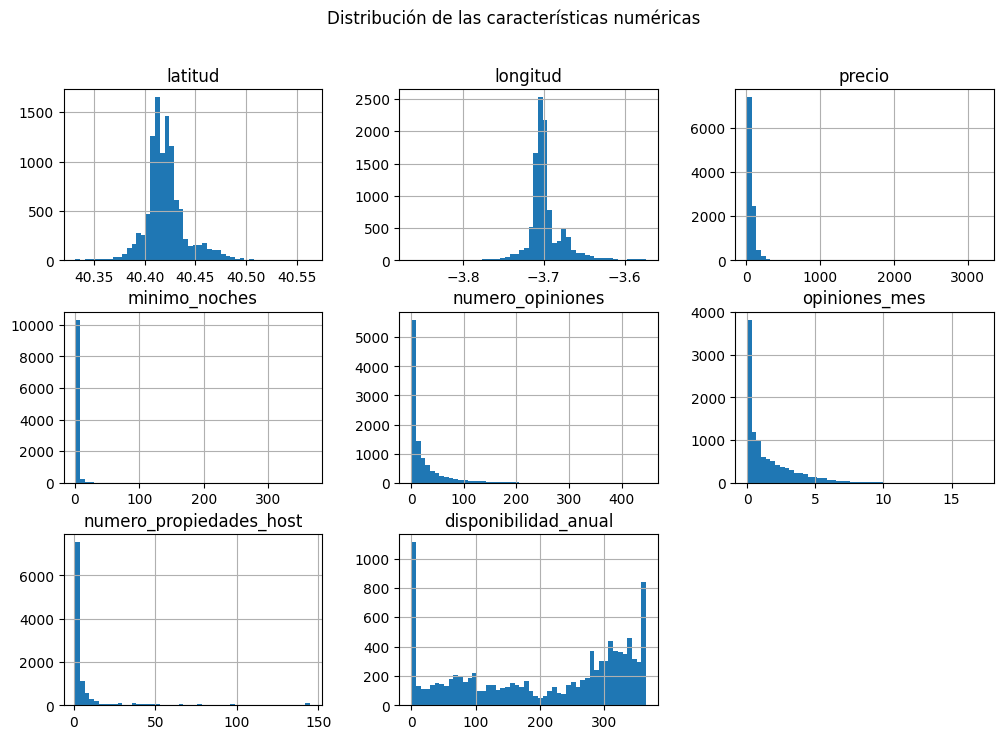

In [16]:
dataset_train.hist(bins=50, figsize=(12, 8))
plt.suptitle('Distribución de las características numéricas')
plt.show()

Observando las distribuciones, podemos observar cuatro grupos diferentes: `latitud` y `longitud`; `disponibilidad_anual`; `precio`, `minimo_noches`,y `numero_propiedades_host`; y `numero_opiniones` y `opiniones_mes`, ya que pueden valer 0.

A cada uno de estos grupos se le aplicará una transformación diferente, adecuada a la distribución que siguen:
- Para el caso de `latitud` y `longitud` se pasará a tener las coordendas `x`, `y` y `z`, definidas tal que:
$$ 
	x = \cos(\text{\verb|latitud|})\times\cos(\text{\verb|longitud|}) \\
	y = \cos(\text{\verb|latitud|})\times\sin(\text{\verb|longitud|}) \\
	z = \sin(\text{\verb|latitud|})
$$
con `latitud` y `longitud` en radianes.
- Para la `disponibilidad_anual` aplicaremos un _bucketizing_. Más concretamente, se dividirá el conjunto 4 utilizando los cuartiles.
- Para `numero_opiniones` y `opiniones_mes` tenemos una distribución claramente sesgada, siguiendo una distribución _power-law_. Para esta distribución no podemos aplicar $\log$, pues existen instancias con valor 0 en estas características y el $\log(0) = -\infty$. Por lo tanto, se aplicará una transformación usando la raíz cuadrada, consiguiendo reducir el tamaño de la cola. Sin embargo, no se consigue cambiar la forma de la distribución, por lo que el escalado que utilizaremos será el escalado robusto, que permite conservar los valores atípicos de estas características.
- Para `minimo_noches` y `numero_propiedades_host` también tenemos una distribución sesgada, en estos casos más notablemente si miramos los cuartiles. En este caso sí podemos aplicar $\log$, pues el valor mínimo que pueden adoptar, por naturaleza, es el 1 (los huéspedes se quedan mínimo una noche y cada propiedad tiene un propietario). Tras aplicar la transformación, vamos a escalar los datos usando de nuevo el escalador robusto, pues tienen valores atípicos notables y no siguen una distribución normal.
- Por último, para `precio` también contamos con una distribución sesgada a la cuál se le puede aplicar una transformación logarítica. Se puede observar que tras las transformación se obtiene una distribución normal, por lo que el escalado elegido será el escalado estándar.

In [17]:
coordenadas_columnas = ['latitud', 'longitud']

class TransformadorCoordenadas(BaseEstimator, TransformerMixin):
    # def __init__(self):

	def transform(self, X : pd.DataFrame):
		'''
		Se tomará como primera columna la latitud y la segunda columna la longitud
		'''
		if isinstance(X, pd.DataFrame):
			X = X.to_numpy()
		
		dimensiones = X.shape
		if dimensiones[1] != 2:
			raise Exception('Los datos no disponen de dos columnas')

		# Matriz para las coordenas x, y, z
		coordenadas_trasnformadas = np.ndarray(shape=(dimensiones[0], 3), dtype=float)

		for fila in range(0, dimensiones[0]):
			coordenadas_trasnformadas[fila] = [
				np.cos(np.deg2rad(X[fila, 0])) * np.cos(np.deg2rad(X[fila, 1])),
				np.cos(np.deg2rad(X[fila, 0])) * np.sin(np.deg2rad(X[fila, 1])),
				np.sin(np.deg2rad(X[fila, 0]))
			]
		
		return coordenadas_trasnformadas

	def fit(self, X, y=None):
		'''
		No hace nada porque la transformación se realiza utilizando un algoritmo
		que no requiere de datos anteriores
		'''
		return self


	def get_feature_names_out(self, names=None):
		return ['x', 'y', 'z']

In [18]:
disponibilidad_columnas = ['disponibilidad_anual']

disponibilidad_pipeline = make_pipeline(
	KBinsDiscretizer(n_bins = 4, encode='onehot-dense', strategy='quantile', 
                  quantile_method='linear', random_state=0)
)

In [19]:
opiniones_columnas = ['numero_opiniones', 'opiniones_mes']

opiniones_pipeline = make_pipeline(
    FunctionTransformer(np.sqrt, feature_names_out="one-to-one"),
    RobustScaler()
)

In [20]:
log_columnas = ['minimo_noches', 'numero_propiedades_host']

log_pipeline = make_pipeline(
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    RobustScaler()
)

In [21]:
precio_columna = ['precio']

precio_pipeline = make_pipeline(
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler()
)

Generamos las duplas para cada una de estas pipelines

In [22]:
transformador_coordendas 	= (TransformadorCoordenadas(), coordenadas_columnas)
transformador_disponibiidad = (disponibilidad_pipeline, disponibilidad_columnas)
transformador_opiniones 	= (opiniones_pipeline, opiniones_columnas)
transformador_log 			= (log_pipeline, log_columnas)
transformador_precio 		= (precio_pipeline, precio_columna)

El conjunto del preprocesamiento quedaría:

In [23]:
# Para los datos de entrada
preprocesamiento = make_column_transformer(
    transformador_barrio_distrito,
    transformador_coordendas,
    transformador_precio,
    transformador_opiniones,
    transformador_log,
    transformador_disponibiidad,
    # Para mantener los nombres de las características
    verbose_feature_names_out=False
)

# Para los datos de salida
preprocesamiento_target = make_column_transformer(
    transformador_habitacion,
    # Para mantener el nombre de la característica
    verbose_feature_names_out=False
)

dataset_procesado = preprocesamiento.fit_transform(dataset_train)
x_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento.get_feature_names_out())

dataset_procesado = preprocesamiento_target.fit_transform(dataset_train)
y_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento_target.get_feature_names_out())

In [24]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10657 entries, 0 to 10656
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   distrito_0                10657 non-null  float64
 1   distrito_1                10657 non-null  float64
 2   distrito_2                10657 non-null  float64
 3   distrito_3                10657 non-null  float64
 4   distrito_4                10657 non-null  float64
 5   barrio_0                  10657 non-null  float64
 6   barrio_1                  10657 non-null  float64
 7   barrio_2                  10657 non-null  float64
 8   barrio_3                  10657 non-null  float64
 9   barrio_4                  10657 non-null  float64
 10  barrio_5                  10657 non-null  float64
 11  barrio_6                  10657 non-null  float64
 12  x                         10657 non-null  float64
 13  y                         10657 non-null  float64
 14  z     

In [25]:
y_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10657 entries, 0 to 10656
Data columns (total 1 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tipo_habitacion  10657 non-null  float64
dtypes: float64(1)
memory usage: 83.4 KB


Se puede definir una función que se encarge de ejecutar estos dos pipelines y devuelva los dos subconjuntos: los datos de entrada al modelo y las etiquetas asociadas a cada instancia.

In [26]:
def generar_x_y(datos):
	'''
	Divide los datos en los conjuntos X e Y, ya preprocesados, para su uso en los
	modelos.
	'''
	x = pd.DataFrame(
		data = preprocesamiento.transform(datos), 
		columns = preprocesamiento.get_feature_names_out()
	)

	y = pd.DataFrame(
		data = preprocesamiento_target.transform(datos), 
		columns = preprocesamiento_target.get_feature_names_out()
	)

	return x,y

### 4. Entrenamiento y validación de los modelos

Antes de entrar a los modelos, generamos los conjuntos X e Y para el test con la función que se acaba de definir.

In [27]:
x_test, y_test = generar_x_y(dataset_test)

#### Naive Bayes

Comenzamos con la cross-validación usando la función `cross_val_score`. Indicamos el parámetro `scoring` con la exactitud y en el número de subdivisiones indicamos 10.

In [28]:
modelo_gausiano = GaussianNB()

resultados_naive_bayer = cross_val_score(modelo_gausiano, x_train, y_train.to_numpy().ravel(), 
                                        cv=10, scoring='accuracy')
resultados_naive_bayer.mean()

np.float64(0.7371683006104168)

Observamos que, de media, se tiene un 73% de exactitud a la hora de clasificar las instancias del conjunto de entrenamiento. 

A continuación entrenamos el modelo con todos los datos de entrenamiento y comprobamos la exactitud con los datos de test.

In [29]:
modelo_gausiano.fit(x_train, y_train.to_numpy().ravel())

y_predicho = modelo_gausiano.predict(x_test)

exactitud_test = accuracy_score(y_test, y_predicho)

print(exactitud_test)

0.7353603603603603


Podemos ver que en el conjunto de test también se obtiene aproximadamente un 73% de exacitud. Viendo en detalle las clases predichas usando una matriz de confusión podemos ver que donde más dificultad tiene es a la hora de predecir las habitaciones compartidas.

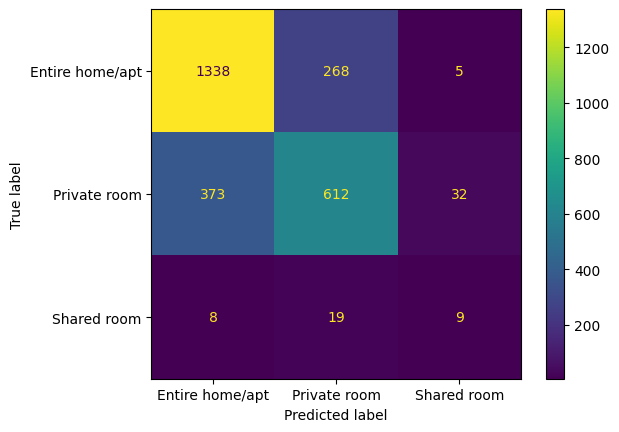

In [30]:
matriz_confusion = confusion_matrix(y_test, y_predicho)

matriz_confusion_grafica = ConfusionMatrixDisplay(
    matriz_confusion, display_labels=dataset['tipo_habitacion'].unique())

matriz_confusion_grafica.plot()
plt.show()

In [ ]:
# joblib.dump(modelo_gausiano, "modelo_gaussiano.pkl")

['modelo_gaussiano.pkl']

#### KNN

En este caso sí que es posible utilizar el objeto `GridSearchCV`. Indicaremos como parámetro a optimizar el número de vecinos a tener en cuenta para hacer decidir la clase. Comprobaremos desde 1 vecino hasta 25 como máximo y ajustaremos los pesos al inverso de la distancia, para que los nodos tengan mayor relevancia a más cerca estén del elemento que se quiera clasificar.

In [31]:
pipeline_knn = Pipeline([
    ("knn", KNeighborsClassifier(weights="distance"))
])

parametros_knn = [
	{'knn__n_neighbors' : list(range(1, 26))}
]

optimizacion_knn = GridSearchCV(pipeline_knn, parametros_knn, cv=10, scoring="accuracy")
optimizacion_knn.fit(x_train, y_train.to_numpy().ravel())

,estimator,Pipeline(step...'distance'))])
,param_grid,"[{'knn__n_neighbors': [1, 2, ...]}]"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,23


In [32]:
print(optimizacion_knn.best_params_)
print(optimizacion_knn.best_score_)

{'knn__n_neighbors': 23}
0.8813929480573245


In [33]:
modelo_knn = optimizacion_knn.best_estimator_

y_predicho = modelo_knn.predict(x_test)

exactitud_test = accuracy_score(y_test, y_predicho)

print(exactitud_test)

0.8971471471471472


Obtenemos para el conjunto de test casi un 90% de acierto con un modelo que usa los 23 vecinos más cercanos. Si observamos la matriz de confusión, podemos apreciar como, de nuevo, se tienen dificultades para clasificar las habitaciones compartidas, aunque mejora notablemente en la clasificación de las habitaciones privadas.

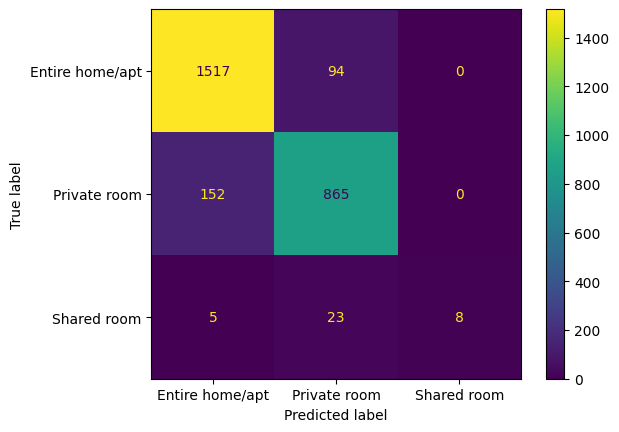

In [34]:
matriz_confusion = confusion_matrix(y_test, y_predicho)

matriz_confusion_grafica = ConfusionMatrixDisplay(
    matriz_confusion, display_labels=dataset['tipo_habitacion'].unique())

matriz_confusion_grafica.plot()
plt.show()

In [ ]:
# joblib.dump(modelo_knn, "modelo_knn.pkl")

['modelo_knn.pkl']

#### Árboles de decisión

Para este tipo de modelos utilizaremos de nuevo el `GridSearchCV`. Los parámetros que tienen que variar son:
- `max_leaf_node` en el intervalo $[2,50]$
- `min_samples_split` en el intervalo $[2,6]$
- `max_depth` en el intervalo $[1,20]$

Además, se indicará el parámetro `class_weight` del modelo con el valor `balanced`, que ajusta el peso de cada clase inversamente proporcional a la frecuencia de dicha clase.

In [35]:
pipeline_arbol = Pipeline([
    ("arbol", DecisionTreeClassifier(class_weight='balanced', random_state=0))
])

parametros_arbol = [
    {
        'arbol__max_leaf_nodes' : list(range(2,51)),
        'arbol__min_samples_split' : list(range(2,7)),
        'arbol__max_depth' : list(range(1,21))
    }
]

optimizacion_arbol = GridSearchCV(pipeline_arbol, parametros_arbol, cv=10, scoring="accuracy")
optimizacion_arbol.fit(x_train, y_train.to_numpy().ravel())

,estimator,Pipeline(step...om_state=0))])
,param_grid,"[{'arbol__max_depth': [1, 2, ...], 'arbol__max_leaf_nodes': [2, 3, ...], 'arbol__min_samples_split': [2, 3, ...]}]"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


Podemos observar cuales han sido los mejores hiperparámetros para el entrenamiento del árbol.

In [37]:
print(optimizacion_arbol.best_params_)
print(optimizacion_arbol.best_score_)

{'arbol__max_depth': 2, 'arbol__max_leaf_nodes': 3, 'arbol__min_samples_split': 2}
0.8339113354297141


In [39]:
modelo_arbol = optimizacion_arbol.best_estimator_

y_predicho = modelo_arbol.predict(x_test)

exactitud_test = accuracy_score(y_test, y_predicho)

print(exactitud_test)

0.8348348348348348


Tras realizar la predicción sobre los datos de test, observamos que el porcentaje de exactitud es de poco más de un 83%.

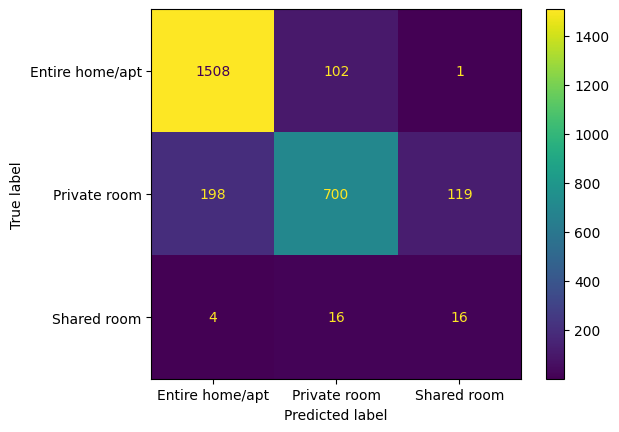

In [40]:
matriz_confusion = confusion_matrix(y_test, y_predicho)

matriz_confusion_grafica = ConfusionMatrixDisplay(
    matriz_confusion, display_labels=dataset['tipo_habitacion'].unique())

matriz_confusion_grafica.plot()
plt.show()

In [ ]:
# joblib.dump(modelo_arbol, "modelo_arbol.pkl")

['modelo_arbol.pkl']

### 5. Conclusión

Tras el entrenamiento de los tres modelos sacamos como conclusiones:
- El modelo gaussiano, al hacer suposiciones sobre la distribución de los datos, es lógico que sea el que produzca un porcentaje de exactitud más bajo. Aún así produce un porcentaje medianamente aceptable y además es capaz de clasificar en un 80% las instancias correspondientes a un apartamento completo.
- Por otro lado, el modelo del árbol de decisión mejora el porcentaje de exactitud hasta más del 83%, notablemente mejor que el modelo gaussiano. La mejora más notable puede ser la clasificación de las habitaciones compartidas, pues clasifica casi un 100% más correctamente que el modelo gaussiano.
- Por último, el mejor modelo en cuanto a exactitud ha sido el KNN, con un porcentaje casi un 90%, destacando notablemente en la clasificación de las habitaciones privadas sobre el modelo del árbol de decisión y en la de los pisos completos sobre el modelo gaussiano. Sin embargo, es peor a la hora de precedir las habitaciones compartidas sobre ambos modelos.

A todos los modelos les ha costado hacer una buena clasificación de las habitaciones compartidas, aunque se puede tratar de algo lógico, pues el número de instancias que se tienen con esa etiqueta es notariamente inferior que los que se tienen con el resto de etiquetas, tanto que puede que incluso las técnicas de balanceo no sean capaces de contrarrestar dicha diferencia.